# 03 | Evaluation and Interpretation
*Project 2 — Machine Learning: From Data to Predictions*

## Notebook 3 of 3: Final held-out evaluation, error analysis, interpretation, and model demo

**This notebook is the final report.** It restates the question and final model, reproduces the deterministic source-file holdout, evaluates the saved tuned pipeline, inspects residuals and segmented errors, estimates permutation importance, and demonstrates saving/reloading the model.

Put differently, this is the standalone report. It restates the decision, target, metric, and limitations, evaluates the tuned pipeline on the pre-defined file-grouped holdout, compares it with the baseline and grouped-CV estimate, interprets feature dependence, and demonstrates loading the saved pipeline for a new prediction. Do not change model choices based on this test result.

---
## 0. Setup

In [1]:
from pathlib import Path
import sys, warnings, json
warnings.filterwarnings("ignore", category=FutureWarning)

ROOT = Path.cwd()
if not (ROOT / "src").exists():
    ROOT = ROOT.parent
if not (ROOT / "src").exists():
    ROOT = ROOT.parent
sys.path.insert(0, str(ROOT / "src"))

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from project_utils import load_polarization_data

pd.set_option("display.max_columns", 100)
sns.set_theme(style="whitegrid")
RANDOM_STATE = 42
FEATURES = ["current_density", "pressure", "relative_humidity", "test_family", "operating_set"]
TARGET = "cell_voltage"
GROUP = "source_file"

data = load_polarization_data()
print(f"Loaded {len(data):,} observations from {data[GROUP].nunique()} source files "
      f"across {data['test_family'].nunique()} test families.")

from sklearn.model_selection import GroupShuffleSplit
from sklearn.dummy import DummyRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
from sklearn.inspection import permutation_importance
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.linear_model import Ridge
from sklearn.ensemble import RandomForestRegressor, ExtraTreesRegressor, GradientBoostingRegressor
import joblib

Loaded 5,005 observations from 26 source files across 9 test families.


---
## 1. The question and the final model

The goal is to predict measured PEM fuel-cell cell voltage from current density and recorded operating context. The final pipeline is the tuned Random Forest selected in notebook 02 using grouped cross-validation on training source files.

The test split holds out complete source files. This is more demanding than randomly splitting rows from the same polarization curves, but it is not equivalent to validation in an independent laboratory or on a new MEA.

In [2]:
# Recreate the deterministic grouped holdout
# The split must match Notebook 2 exactly. No fitting or tuning is performed on the holdout.
splitter = GroupShuffleSplit(n_splits=1, test_size=0.22, random_state=RANDOM_STATE)
train_idx, test_idx = next(splitter.split(data, data[TARGET], groups=data[GROUP]))
train, test = data.iloc[train_idx].copy(), data.iloc[test_idx].copy()
assert set(train[GROUP]).isdisjoint(set(test[GROUP]))
X_train, y_train = train[FEATURES], train[TARGET]
X_test, y_test = test[FEATURES], test[TARGET]

model_path = ROOT / "best_model.joblib"
if not model_path.exists():
    raise FileNotFoundError("Run notebook 02 first to create best_model.joblib.")
tuned_model = joblib.load(model_path)
print(f"Training: {len(train):,} rows / {train[GROUP].nunique()} source files")
print(f"Test: {len(test):,} rows / {test[GROUP].nunique()} held-out source files")
print("Source-file overlap:", set(train[GROUP]) & set(test[GROUP]))

Training: 3,692 rows / 20 source files
Test: 1,313 rows / 6 held-out source files
Source-file overlap: set()


---
## 2. Test once

Evaluate the preselected tuned model and mean baseline on the held-out files. The baseline predicts the training-set mean for every test row. The table is saved so the reported results can be traced to this evaluation run.

MAE is the average absolute error in volts. RMSE penalizes larger errors more strongly. R² compares the model with a constant prediction relative to the test-target variance; it can be negative when predictions are worse than the test-set mean benchmark.

In [3]:
pred = tuned_model.predict(X_test)
baseline_pred = np.repeat(y_train.mean(), len(y_test))

def calculate_metrics(y_true, y_pred):
    return {
        "MAE_V": mean_absolute_error(y_true, y_pred),
        "RMSE_V": mean_squared_error(y_true, y_pred) ** 0.5,
        "R2": r2_score(y_true, y_pred),
    }

evaluation = pd.DataFrame([
    {"model": "Mean baseline", **calculate_metrics(y_test, baseline_pred)},
    {"model": "Tuned Random Forest", **calculate_metrics(y_test, pred)},
]).sort_values("MAE_V")
display(evaluation.round(5))
evaluation.to_csv(ROOT / "final_test_metrics.csv", index=False)

# Compare the final test MAE with the best grouped-CV selection estimate.
tuning_file = ROOT / "tuning_results.csv"
if tuning_file.exists():
    tuning_saved = pd.read_csv(tuning_file)
    best_cv_mae = -tuning_saved.loc[tuning_saved["rank_test_score"].idxmin(), "mean_test_score"]
    print(f"Best grouped-CV MAE from tuning (V): {best_cv_mae:.5f}")
print(f"Held-out tuned Random Forest MAE (V): {evaluation.loc[evaluation['model'].eq('Tuned Random Forest'), 'MAE_V'].iloc[0]:.5f}")
print("Held-out files:", sorted(test[GROUP].unique()))

,model,MAE_V,RMSE_V,R2
1,Tuned Random Forest,0.06638,0.09038,0.84145
0,Mean baseline,0.19650,0.22708,-0.00087


Best grouped-CV MAE from tuning (V): 0.08505
Held-out tuned Random Forest MAE (V): 0.06638
Held-out files: ['Activation Test MEA Constant Current 0.25A/4.csv', 'Activation Test MEA Constant Voltage 0.6V-3/6.csv', 'Activation Test MEA Constant Voltage 0.6V-4/4.csv', 'Activation Test MEA Constant Voltage 0.6V-4/6.csv', 'Activation Test MEA Cycling Potential/5.csv', 'Standard Test of Nafion Membrane 112/1.csv']


---
## 3. Where it goes wrong

Use predicted-versus-observed voltage and residual plots to inspect systematic patterns. A strong overall metric can hide bias at particular voltage ranges or experimental conditions. Residuals are defined as observed minus predicted voltage.

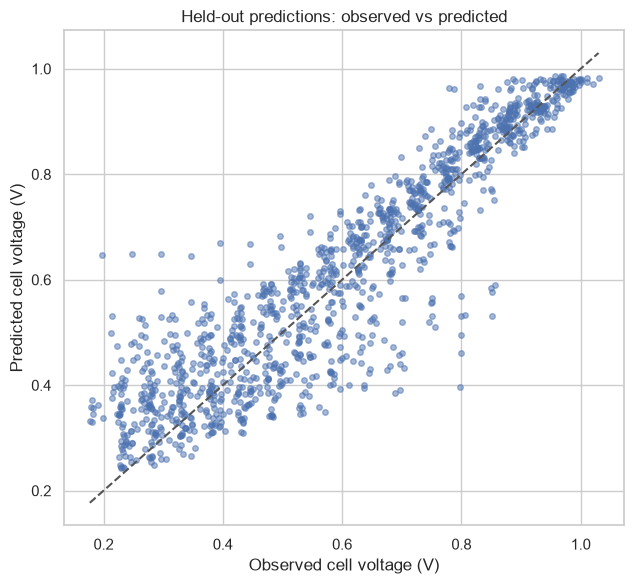

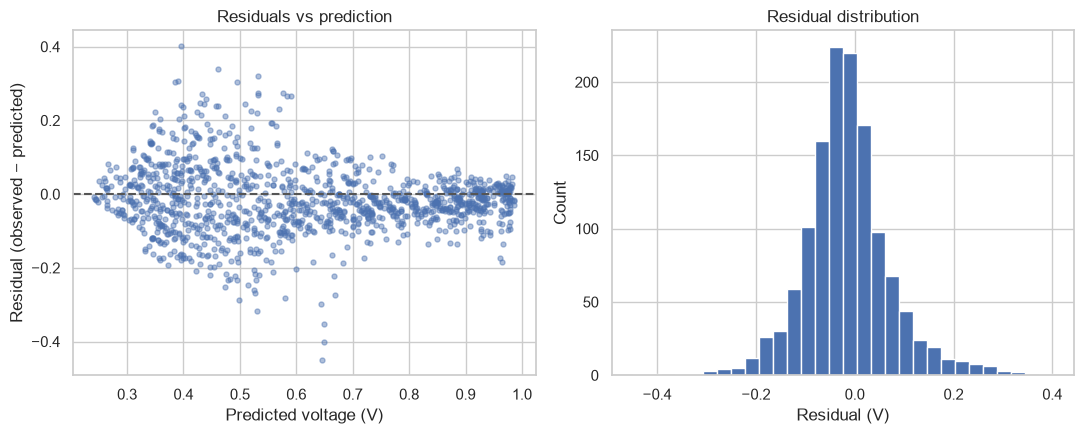

Largest absolute errors:


,source_file,test_family,current_density,pressure,relative_humidity,observed_cell_voltage_V,prediction,residual_V,absolute_error_V
2433,Activation Test MEA Cycling Potential/5.csv,Activation Test MEA Cycling Potential,789.0,5.0,50.0,0.197,0.646082,-0.449082,0.449082
33,Activation Test MEA Constant Current 0.25A/4.csv,Activation Test MEA Constant Current 0.25A,396.0,5.0,100.0,0.797,0.395634,0.401366,0.401366
2432,Activation Test MEA Cycling Potential/5.csv,Activation Test MEA Cycling Potential,762.0,5.0,50.0,0.247,0.648320,-0.401320,0.401320
2431,Activation Test MEA Cycling Potential/5.csv,Activation Test MEA Cycling Potential,743.0,5.0,50.0,0.296,0.648949,-0.352949,0.352949
81,Activation Test MEA Constant Current 0.25A/4.csv,Activation Test MEA Constant Current 0.25A,518.0,15.0,100.0,0.800,0.461498,0.338502,0.338502
1958,Activation Test MEA Constant Voltage 0.6V-4/4.csv,Activation Test MEA Constant Voltage 0.6V-4,317.0,25.0,100.0,0.851,0.531462,0.319538,0.319538
2495,Activation Test MEA Cycling Potential/5.csv,Activation Test MEA Cycling Potential,1250.0,25.0,50.0,0.215,0.530927,-0.315927,0.315927
1852,Activation Test MEA Constant Voltage 0.6V-4/4.csv,Activation Test MEA Constant Voltage 0.6V-4,1060.0,5.0,50.0,0.697,0.390748,0.306252,0.306252
1869,Activation Test MEA Constant Voltage 0.6V-4/4.csv,Activation Test MEA Constant Voltage 0.6V-4,451.0,5.0,100.0,0.800,0.495409,0.304591,0.304591
24,Activation Test MEA Constant Current 0.25A/4.csv,Activation Test MEA Constant Current 0.25A,1140.0,5.0,50.0,0.688,0.384806,0.303194,0.303194


In [4]:
predictions = test.copy()
predictions["observed_cell_voltage_V"] = y_test.to_numpy()
predictions["prediction"] = pred
predictions["residual_V"] = predictions["observed_cell_voltage_V"] - predictions["prediction"]
predictions["absolute_error_V"] = predictions["residual_V"].abs()
predictions.to_csv(ROOT / "final_test_predictions.csv", index=False)

fig, ax = plt.subplots(figsize=(6.5, 6))
ax.scatter(y_test, pred, s=16, alpha=.5)
lo, hi = min(y_test.min(), pred.min()), max(y_test.max(), pred.max())
ax.plot([lo, hi], [lo, hi], linestyle="--", color="#555555")
ax.set(xlabel="Observed cell voltage (V)", ylabel="Predicted cell voltage (V)",
       title="Held-out predictions: observed vs predicted")
fig.tight_layout()
fig.savefig(ROOT / "final_predicted_vs_observed.png", dpi=220, bbox_inches="tight")
plt.show()

fig, axes = plt.subplots(1, 2, figsize=(11, 4.5))
axes[0].scatter(pred, predictions["residual_V"], s=13, alpha=.45)
axes[0].axhline(0, linestyle="--", color="#555555")
axes[0].set(xlabel="Predicted voltage (V)", ylabel="Residual (observed − predicted)",
            title="Residuals vs prediction")
axes[1].hist(predictions["residual_V"], bins=30, edgecolor="white")
axes[1].set(xlabel="Residual (V)", ylabel="Count", title="Residual distribution")
fig.tight_layout()
fig.savefig(ROOT / "final_residual_diagnostics.png", dpi=220, bbox_inches="tight")
plt.show()

print("Largest absolute errors:")
display(predictions.nlargest(10, "absolute_error_V")[
    [GROUP, "test_family", "current_density", "pressure", "relative_humidity",
     "observed_cell_voltage_V", "prediction", "residual_V", "absolute_error_V"]
])

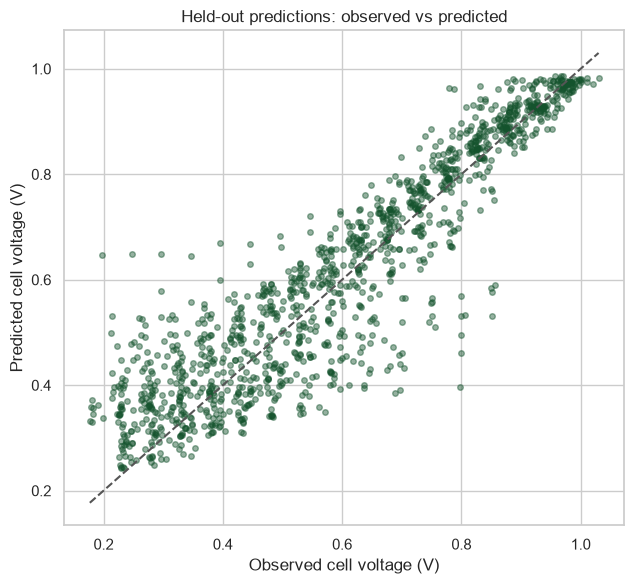

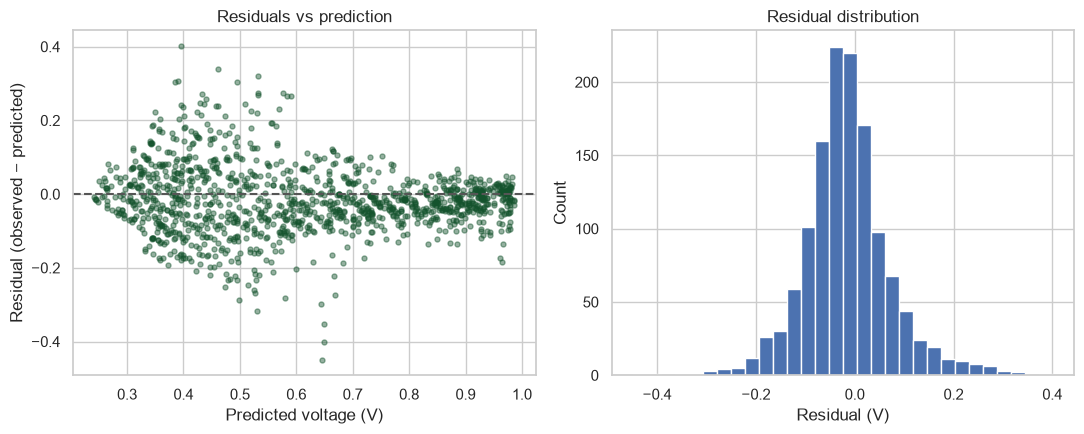

Largest absolute errors:


,source_file,test_family,current_density,pressure,relative_humidity,observed_cell_voltage_V,prediction,residual_V,absolute_error_V
2433,Activation Test MEA Cycling Potential/5.csv,Activation Test MEA Cycling Potential,789.0,5.0,50.0,0.197,0.646082,-0.449082,0.449082
33,Activation Test MEA Constant Current 0.25A/4.csv,Activation Test MEA Constant Current 0.25A,396.0,5.0,100.0,0.797,0.395634,0.401366,0.401366
2432,Activation Test MEA Cycling Potential/5.csv,Activation Test MEA Cycling Potential,762.0,5.0,50.0,0.247,0.648320,-0.401320,0.401320
2431,Activation Test MEA Cycling Potential/5.csv,Activation Test MEA Cycling Potential,743.0,5.0,50.0,0.296,0.648949,-0.352949,0.352949
81,Activation Test MEA Constant Current 0.25A/4.csv,Activation Test MEA Constant Current 0.25A,518.0,15.0,100.0,0.800,0.461498,0.338502,0.338502
1958,Activation Test MEA Constant Voltage 0.6V-4/4.csv,Activation Test MEA Constant Voltage 0.6V-4,317.0,25.0,100.0,0.851,0.531462,0.319538,0.319538
2495,Activation Test MEA Cycling Potential/5.csv,Activation Test MEA Cycling Potential,1250.0,25.0,50.0,0.215,0.530927,-0.315927,0.315927
1852,Activation Test MEA Constant Voltage 0.6V-4/4.csv,Activation Test MEA Constant Voltage 0.6V-4,1060.0,5.0,50.0,0.697,0.390748,0.306252,0.306252
1869,Activation Test MEA Constant Voltage 0.6V-4/4.csv,Activation Test MEA Constant Voltage 0.6V-4,451.0,5.0,100.0,0.800,0.495409,0.304591,0.304591
24,Activation Test MEA Constant Current 0.25A/4.csv,Activation Test MEA Constant Current 0.25A,1140.0,5.0,50.0,0.688,0.384806,0.303194,0.303194


In [5]:
predictions = test.copy()
predictions["observed_cell_voltage_V"] = y_test.to_numpy()
predictions["prediction"] = pred
predictions["residual_V"] = predictions["observed_cell_voltage_V"] - predictions["prediction"]
predictions["absolute_error_V"] = predictions["residual_V"].abs()
predictions.to_csv(ROOT / "final_test_predictions.csv", index=False)

fig, ax = plt.subplots(figsize=(6.5, 6))
ax.scatter(y_test, pred, s=16, alpha=.45, color="#14532D")
lo, hi = min(y_test.min(), pred.min()), max(y_test.max(), pred.max())
ax.plot([lo, hi], [lo, hi], linestyle="--", color="#555555")
ax.set(xlabel="Observed cell voltage (V)", ylabel="Predicted cell voltage (V)",
       title="Held-out predictions: observed vs predicted")
fig.tight_layout()
fig.savefig(ROOT / "final_predicted_vs_observed.png", dpi=220, bbox_inches="tight")
plt.show()

fig, axes = plt.subplots(1, 2, figsize=(11, 4.5))
axes[0].scatter(pred, predictions["residual_V"], s=13, alpha=.45, color="#14532D")
axes[0].axhline(0, linestyle="--", color="#555555")
axes[0].set(xlabel="Predicted voltage (V)", ylabel="Residual (observed − predicted)",
            title="Residuals vs prediction")
axes[1].hist(predictions["residual_V"], bins=30, edgecolor="white")
axes[1].set(xlabel="Residual (V)", ylabel="Count", title="Residual distribution")
fig.tight_layout()
fig.savefig(ROOT / "final_residual_diagnostics.png", dpi=220, bbox_inches="tight")
plt.show()

print("Largest absolute errors:")
display(predictions.nlargest(10, "absolute_error_V")[
    [GROUP, "test_family", "current_density", "pressure", "relative_humidity",
     "observed_cell_voltage_V", "prediction", "residual_V", "absolute_error_V"]
])

## Segmented errors and a practical prediction demo

Overall scores can conceal protocol-specific failures. The following table reports MAE by test family and source file on the held-out set. These groups are small and heterogeneous, so use them as diagnostic evidence rather than definitive rankings. The final pipeline is also loaded from disk and used to predict a few held-out examples, demonstrating that the saved artifact is reusable.

,segment_type,segment,n_rows,MAE_V,RMSE_V
9,source_file,Activation Test MEA Cycling Potential/5.csv,93,0.110144,0.144463
5,source_file,Activation Test MEA Constant Current 0.25A/4.csv,141,0.091289,0.121588
7,source_file,Activation Test MEA Constant Voltage 0.6V-4/4.csv,143,0.081635,0.110997
8,source_file,Activation Test MEA Constant Voltage 0.6V-4/6.csv,142,0.058310,0.078142
10,source_file,Standard Test of Nafion Membrane 112/1.csv,651,0.057947,0.073213
6,source_file,Activation Test MEA Constant Voltage 0.6V-3/6.csv,143,0.044524,0.063744
3,test_family,Activation Test MEA Cycling Potential,93,0.110144,0.144463
0,test_family,Activation Test MEA Constant Current 0.25A,141,0.091289,0.121588
2,test_family,Activation Test MEA Constant Voltage 0.6V-4,285,0.070013,0.096043
4,test_family,Standard Test of Nafion Membrane 112,651,0.057947,0.073213


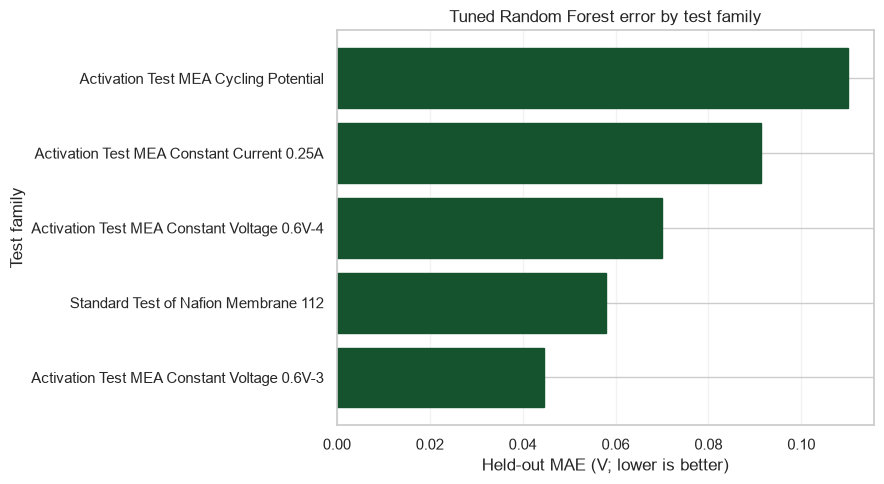

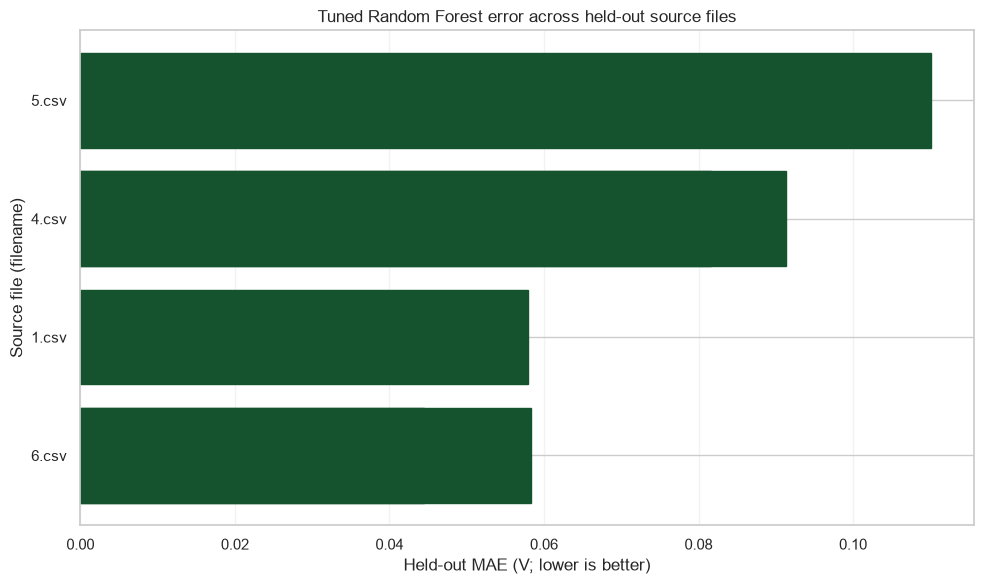

,current_density,pressure,relative_humidity,test_family,operating_set,predicted_cell_voltage_V
0,2550.0,5.0,30.0,Activation Test MEA Constant Current 0.25A,not_recorded,0.357442
1,2380.0,5.0,30.0,Activation Test MEA Constant Current 0.25A,not_recorded,0.381252
2,2180.0,5.0,30.0,Activation Test MEA Constant Current 0.25A,not_recorded,0.370826
3,1950.0,5.0,30.0,Activation Test MEA Constant Current 0.25A,not_recorded,0.388531
4,1690.0,5.0,30.0,Activation Test MEA Constant Current 0.25A,not_recorded,0.398705


The serialized pipeline reloaded successfully and generated predictions for new rows.


In [6]:
predictions = test.copy()
predictions["prediction"] = pred

segment_rows = []
for group_name, group_df in predictions.groupby("test_family"):
    segment_rows.append({"segment_type": "test_family", "segment": group_name,
                         "n_rows": len(group_df), "MAE_V": mean_absolute_error(group_df[TARGET], group_df["prediction"]),
                         "RMSE_V": mean_squared_error(group_df[TARGET], group_df["prediction"]) ** 0.5})
for group_name, group_df in predictions.groupby(GROUP):
    segment_rows.append({"segment_type": "source_file", "segment": group_name,
                         "n_rows": len(group_df), "MAE_V": mean_absolute_error(group_df[TARGET], group_df["prediction"]),
                         "RMSE_V": mean_squared_error(group_df[TARGET], group_df["prediction"]) ** 0.5})
segmented_errors = pd.DataFrame(segment_rows).sort_values(["segment_type", "MAE_V"], ascending=[True, False])
display(segmented_errors)
segmented_errors.to_csv(ROOT / "segmented_error_analysis.csv", index=False)

# Presentation plot: held-out error by protocol/test family.
family_errors = segmented_errors[segmented_errors["segment_type"] == "test_family"].sort_values("MAE_V")
fig, ax = plt.subplots(figsize=(9, 5))
ax.barh(family_errors["segment"], family_errors["MAE_V"], color="#14532D", edgecolor="#14532D")
ax.set(xlabel="Held-out MAE (V; lower is better)", ylabel="Test family",
       title="Tuned Random Forest error by test family")
ax.grid(axis="x", alpha=.25)
fig.tight_layout()
fig.savefig(ROOT / "segmented_error_by_test_family.png", dpi=220, bbox_inches="tight")
plt.show()

# Plot the 12 held-out source files with the largest sample counts to reveal
# whether performance varies substantially between complete experimental files.
file_errors = segmented_errors[segmented_errors["segment_type"] == "source_file"].copy()
file_errors = file_errors.nlargest(12, "n_rows").sort_values("MAE_V")
fig, ax = plt.subplots(figsize=(10, 6))
ax.barh(file_errors["segment"].map(lambda value: str(value).split("/")[-1]), file_errors["MAE_V"], color="#14532D", edgecolor="#14532D")
ax.set(xlabel="Held-out MAE (V; lower is better)", ylabel="Source file (filename)",
       title="Tuned Random Forest error across held-out source files")
ax.grid(axis="x", alpha=.25)
fig.tight_layout()
fig.savefig(ROOT / "segmented_error_by_source_file.png", dpi=220, bbox_inches="tight")
plt.show()

# Reload the saved model from disk (not the in-memory search object) and demonstrate prediction.
reloaded_model = joblib.load(model_path)
demo_rows = X_test.head(5).copy()
demo_predictions = reloaded_model.predict(demo_rows)
demo = demo_rows.copy()
demo["predicted_cell_voltage_V"] = demo_predictions
display(demo)
demo.to_csv(ROOT / "demo_predictions.csv", index=False)
print("The serialized pipeline reloaded successfully and generated predictions for new rows.")


---
## 3A. Error by test family and source file

Segmented metrics help reveal whether errors are concentrated in particular experimental protocols or files. These differences may reflect genuine operating differences, protocol effects, data quality, or limited representation in training. They should not automatically be interpreted as measurement error.

,segment_type,segment,n_rows,MAE_V,RMSE_V
9,source_file,Activation Test MEA Cycling Potential/5.csv,93,0.110144,0.144463
5,source_file,Activation Test MEA Constant Current 0.25A/4.csv,141,0.091289,0.121588
7,source_file,Activation Test MEA Constant Voltage 0.6V-4/4.csv,143,0.081635,0.110997
8,source_file,Activation Test MEA Constant Voltage 0.6V-4/6.csv,142,0.058310,0.078142
10,source_file,Standard Test of Nafion Membrane 112/1.csv,651,0.057947,0.073213
6,source_file,Activation Test MEA Constant Voltage 0.6V-3/6.csv,143,0.044524,0.063744
3,test_family,Activation Test MEA Cycling Potential,93,0.110144,0.144463
0,test_family,Activation Test MEA Constant Current 0.25A,141,0.091289,0.121588
2,test_family,Activation Test MEA Constant Voltage 0.6V-4,285,0.070013,0.096043
4,test_family,Standard Test of Nafion Membrane 112,651,0.057947,0.073213


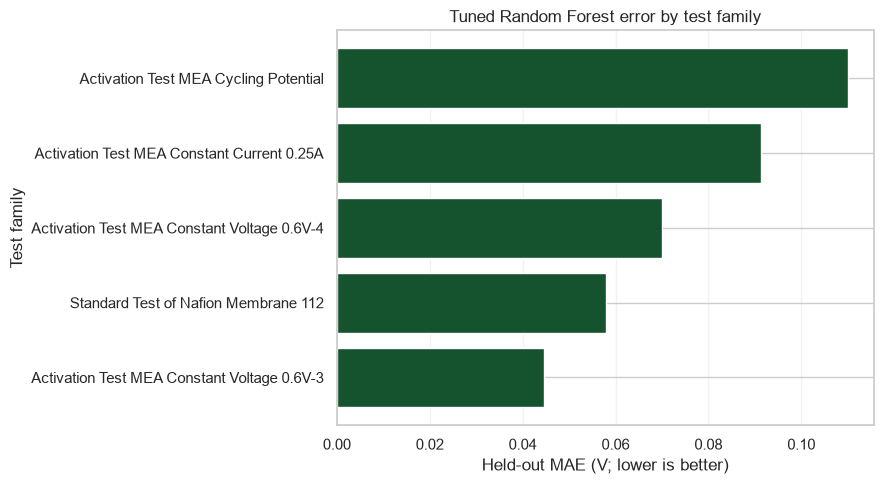

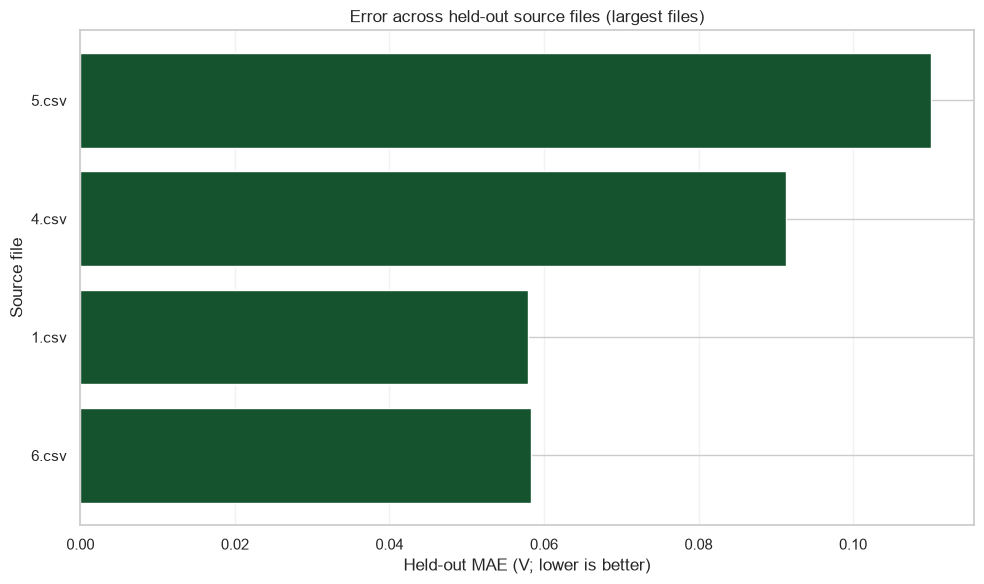

In [7]:
segment_rows = []
for family, group_df in predictions.groupby("test_family"):
    segment_rows.append({
        "segment_type": "test_family", "segment": family, "n_rows": len(group_df),
        "MAE_V": mean_absolute_error(group_df[TARGET], group_df["prediction"]),
        "RMSE_V": mean_squared_error(group_df[TARGET], group_df["prediction"]) ** 0.5
    })
for source_file, group_df in predictions.groupby(GROUP):
    segment_rows.append({
        "segment_type": "source_file", "segment": source_file, "n_rows": len(group_df),
        "MAE_V": mean_absolute_error(group_df[TARGET], group_df["prediction"]),
        "RMSE_V": mean_squared_error(group_df[TARGET], group_df["prediction"]) ** 0.5
    })
segmented_errors = pd.DataFrame(segment_rows).sort_values(
    ["segment_type", "MAE_V"], ascending=[True, False])
display(segmented_errors)
segmented_errors.to_csv(ROOT / "segmented_error_analysis.csv", index=False)

family_errors = segmented_errors[segmented_errors["segment_type"] == "test_family"].sort_values("MAE_V")
fig, ax = plt.subplots(figsize=(9, 5))
ax.barh(family_errors["segment"], family_errors["MAE_V"], color="#14532D")
ax.set(xlabel="Held-out MAE (V; lower is better)", ylabel="Test family",
       title="Tuned Random Forest error by test family")
ax.grid(axis="x", alpha=.25)
fig.tight_layout()
fig.savefig(ROOT / "segmented_error_by_test_family.png", dpi=220, bbox_inches="tight")
plt.show()

file_errors = segmented_errors[segmented_errors["segment_type"] == "source_file"].copy()
file_errors = file_errors.nlargest(12, "n_rows").sort_values("MAE_V")
fig, ax = plt.subplots(figsize=(10, 6))
ax.barh(file_errors["segment"].map(lambda value: str(value).split("/")[-1]),
        file_errors["MAE_V"], color="#14532D")
ax.set(xlabel="Held-out MAE (V; lower is better)", ylabel="Source file",
       title="Error across held-out source files (largest files)")
ax.grid(axis="x", alpha=.25)
fig.tight_layout()
fig.savefig(ROOT / "segmented_error_by_source_file.png", dpi=220, bbox_inches="tight")
plt.show()

---
## 4. What drives the predictions - Model interpretation: permutation importance

Permutation importance measures how much the model score worsens when one feature is shuffled. It is a measure of predictive reliance, not causality. Correlated features can share or mask importance, and the ranking can depend on the held-out sample. Simply put, permutation importance measures the score degradation when one input column is shuffled on the held-out data. It is a model-dependent diagnostic, not a causal effect; correlated predictors can share or mask importance.

,feature,importance_mean,importance_std
0,current_density,0.189332,0.001177
3,test_family,0.015415,0.001340
4,operating_set,0.006643,0.000638
1,pressure,0.004856,0.000744
2,relative_humidity,0.000255,0.000446


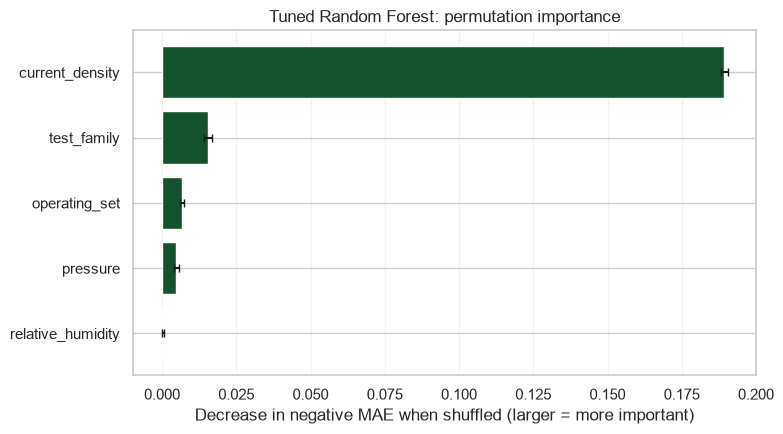

In [8]:
# Importance is computed for the tuned model on the held-out data for interpretation only.
importance = permutation_importance(
    tuned_model, X_test, y_test, scoring="neg_mean_absolute_error",
    n_repeats=4, random_state=RANDOM_STATE, n_jobs=1, max_samples=0.6
)
imp = pd.DataFrame({
    "feature": FEATURES,
    "importance_mean": importance.importances_mean,
    "importance_std": importance.importances_std
}).sort_values("importance_mean")
display(imp.sort_values("importance_mean", ascending=False))
imp.to_csv(ROOT / "permutation_importance.csv", index=False)

fig, ax = plt.subplots(figsize=(8, 4.5))
ax.barh(imp["feature"], imp["importance_mean"], xerr=imp["importance_std"],
        capsize=3, color="#14532D")
ax.set(xlabel="Decrease in negative MAE when shuffled (larger = more important)",
       title="Tuned Random Forest: permutation importance")
ax.grid(axis="x", alpha=.25)
fig.tight_layout()
fig.savefig(ROOT / "permutation_importance.png", dpi=220, bbox_inches="tight")
plt.show()

---
## 5. Save, reload, predict

The fitted pipeline is already saved by notebook 02. Reload it from disk and generate predictions for several rows to verify that the serialized pipeline includes preprocessing and can be used without rebuilding the transformations manually.

In [9]:
reloaded_model = joblib.load(model_path)
demo_rows = X_test.head(5).copy()
demo_predictions = reloaded_model.predict(demo_rows)
demo = demo_rows.copy()
demo["predicted_cell_voltage_V"] = demo_predictions
display(demo)
demo.to_csv(ROOT / "demo_predictions.csv", index=False)
print("Reload successful; predictions generated for five held-out rows.")
print("Saved model:", model_path)

,current_density,pressure,relative_humidity,test_family,operating_set,predicted_cell_voltage_V
0,2550.0,5.0,30.0,Activation Test MEA Constant Current 0.25A,not_recorded,0.357442
1,2380.0,5.0,30.0,Activation Test MEA Constant Current 0.25A,not_recorded,0.381252
2,2180.0,5.0,30.0,Activation Test MEA Constant Current 0.25A,not_recorded,0.370826
3,1950.0,5.0,30.0,Activation Test MEA Constant Current 0.25A,not_recorded,0.388531
4,1690.0,5.0,30.0,Activation Test MEA Constant Current 0.25A,not_recorded,0.398705


Reload successful; predictions generated for five held-out rows.
Saved model: /Users/theophiluskobinasarpey/Documents/DSML_SEP2026 | IRONHACK/Week 6/Day 5/project-2-ml/TKSarpey_Project2_ML_From Data to Prediction/best_model.joblib


,Observed voltage (V),Predicted voltage (V),Absolute error (V)
0,0.296,0.3574,0.0614
1,0.565,0.6521,0.0871
2,0.272,0.3518,0.0798


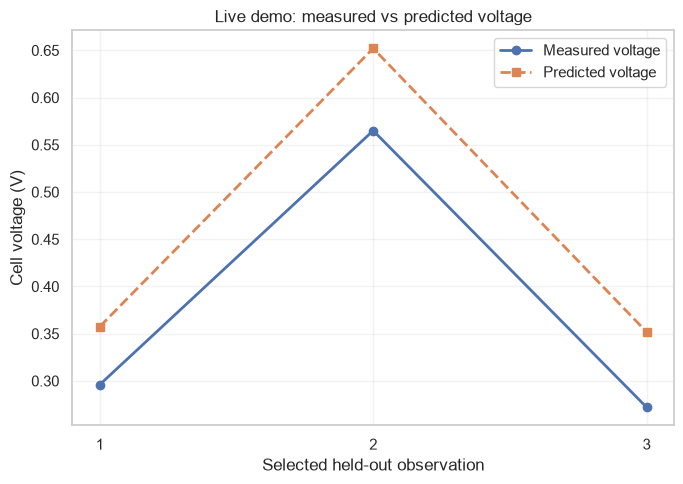

In [10]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# Select three observations spread across the held-out test set.
positions = sorted(set([
    0,
    len(X_test) // 2,
    len(X_test) - 1
]))

demo_X = X_test.iloc[positions].copy()

# Predict voltage using the fitted pipeline.
predicted_voltage = tuned_model.predict(demo_X)

# Recover the measured voltage for the same observations.
if hasattr(y_test, "iloc"):
    observed_voltage = y_test.iloc[positions].to_numpy()
else:
    observed_voltage = np.asarray(y_test)[positions]

# Present a compact, readable comparison.
demo_results = pd.DataFrame({
    "Observed voltage (V)": observed_voltage,
    "Predicted voltage (V)": predicted_voltage,
})

demo_results["Absolute error (V)"] = (
    demo_results["Observed voltage (V)"]
    - demo_results["Predicted voltage (V)"]
).abs()

display(demo_results.round(4))

# Compare predictions with measurements.
fig, ax = plt.subplots(figsize=(7, 5))

sample_numbers = np.arange(1, len(demo_results) + 1)

ax.plot(
    sample_numbers,
    demo_results["Observed voltage (V)"],
    marker="o",
    linewidth=2,
    label="Measured voltage",
)

ax.plot(
    sample_numbers,
    demo_results["Predicted voltage (V)"],
    marker="s",
    linestyle="--",
    linewidth=2,
    label="Predicted voltage",
)

ax.set(
    xlabel="Selected held-out observation",
    ylabel="Cell voltage (V)",
    title="Live demo: measured vs predicted voltage",
    xticks=sample_numbers,
)

ax.grid(alpha=0.25)
ax.legend()
fig.tight_layout()
plt.show()

---
## 6. Conclusions, limitations, and responsible interpretation

A lower MAE/RMSE than the mean baseline indicates predictive value for this split; negative or low R² can occur when the held-out protocols differ substantially from training.

### What the results support
- A reproducible pipeline predicts cell voltage from the selected polarization-curve records.
- Group-aware splitting reduces leakage from related points within the same source file.
- The tuned Random Forest is compared with a mean baseline on source files excluded from fitting and tuning.

### What the results do not establish
- This is not external validation on a different laboratory, MEA, or measurement campaign.
- Test-family differences may be confounded with operating conditions and source-file characteristics.
- Permutation importance does not establish physical causality.
- A useful deployment tolerance must be defined by the intended engineering decision, not by the score alone.

**Limitations**
- The archive combines multiple test protocols, operating conditions, and repeated measurement curves.
- Holding out complete files reduces within-curve leakage but does not guarantee independence across related protocols.
- Missing pressure/humidity values are imputed; missingness may itself reflect protocol design.
- This is prediction, not causal inference. Do not interpret permutation importance as the physical effect of changing a condition.
- Generalization to other cells, membranes, laboratories, or catalyst compositions requires external validation.

**Reproducibility:** fixed random seed 42; grouped holdout; grouped CV; preprocessing inside pipelines; model, tuning results, metrics, predictions, and figures saved in the project root.

### Next steps
1. Validate on an independent experiment or laboratory.
2. Define an acceptable voltage-error tolerance with domain experts.
3. Confirm which features are available at the moment a real prediction would be made.
4. Preserve the source-file grouping and leakage checks in future experiments.

**Main takeaway:** the credibility of a machine-learning result depends on the data split, preprocessing, fair comparison, and honest interpretation—not just the algorithm with the lowest score.